# Improved FER-2013 Expression Classification

Run the code cells **from top to bottom** in Google Colab. The original `FER2013` and `FER2013_Model` folder names and model filenames are preserved.

## Cell 1: IMPORT LIBRARIES

In [27]:
# 1. IMPORT LIBRARIES
import os
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import MobileNetV2
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    recall_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Cell 2: GOOGLE DRIVE

In [28]:
# 2. GOOGLE DRIVE
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cell 3: PATHS - DO NOT CHANGE THESE FOLDER NAMES

In [29]:
# 3. PATHS - DO NOT CHANGE THESE FOLDER NAMES
DATA_DIR = Path("/content/drive/MyDrive/FER2013")
OUTPUT_DIR = Path("/content/drive/MyDrive/FER2013_Model")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = OUTPUT_DIR / "face_emotion_mobilenetv2.keras"
LABELS_PATH = OUTPUT_DIR / "emotion_labels.json"

# Additional evaluation outputs are saved inside the same output folder.
REPORT_PATH = OUTPUT_DIR / "classification_report.csv"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"

IMG_SIZE = 96
BATCH_SIZE = 16
EPOCHS_HEAD = 15
EPOCHS_FINE = 10
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dataset folder not found: {DATA_DIR}")

## Cell 4: READ DATASET

anger          : 136 images
contempt       : 54 images
disgust        : 177 images
fear           : 75 images
happy          : 207 images
sadness        : 84 images
surprise       : 249 images

Emotion classes: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Total images: 982
Class mapping: {'anger': 0, 'contempt': 1, 'disgust': 2, 'fear': 3, 'happy': 4, 'sadness': 5, 'surprise': 6}


,Emotion,Image count
0,anger,136
1,contempt,54
2,disgust,177
3,fear,75
4,happy,207
5,sadness,84
6,surprise,249


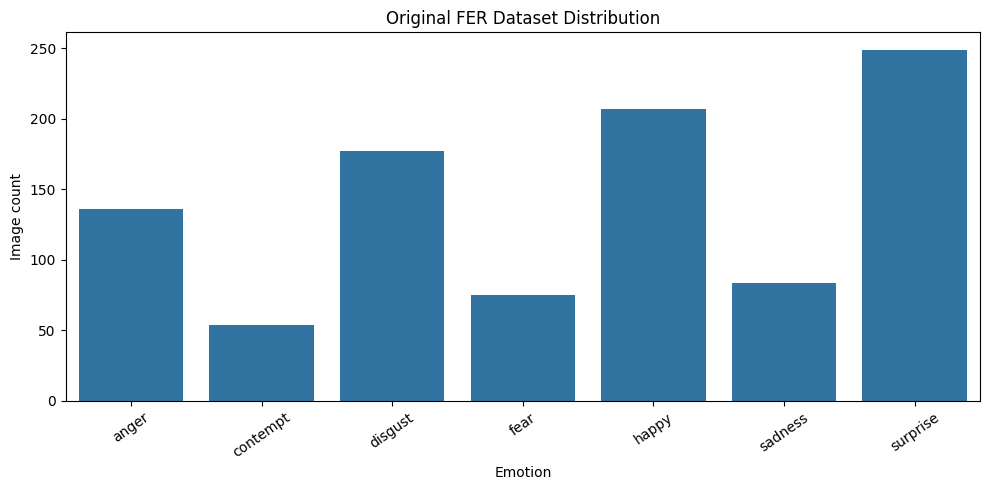

In [30]:
# 4. READ DATASET
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

class_names = sorted(
    p.name for p in DATA_DIR.iterdir()
    if p.is_dir() and not p.name.startswith(".")
)

if len(class_names) < 2:
    raise ValueError(
        f"Expected emotion subfolders inside {DATA_DIR}. Found: {class_names}"
    )

class_to_index = {name: i for i, name in enumerate(class_names)}

file_paths = []
labels = []

for class_name in class_names:
    class_dir = DATA_DIR / class_name
    class_files = sorted(
        p for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    print(f"{class_name:15s}: {len(class_files)} images")

    for path in class_files:
        file_paths.append(str(path))
        labels.append(class_to_index[class_name])

file_paths = np.asarray(file_paths)
labels = np.asarray(labels, dtype=np.int32)

if len(file_paths) == 0:
    raise ValueError("No images found. Check the emotion folders.")

print("\nEmotion classes:", class_names)
print("Total images:", len(file_paths))
print("Class mapping:", class_to_index)

# Plot original class distribution
class_counts = Counter(labels)
distribution = pd.DataFrame({
    "Emotion": class_names,
    "Image count": [class_counts.get(i, 0) for i in range(len(class_names))]
})
display(distribution)

plt.figure(figsize=(10, 5))
sns.barplot(data=distribution, x="Emotion", y="Image count")
plt.title("Original FER Dataset Distribution")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## Cell 5: STRATIFIED TRAIN / VALIDATION / TEST SPLIT

In [31]:
# 5. STRATIFIED TRAIN / VALIDATION / TEST SPLIT
# Test data is held out and is not used for model selection.
counts = Counter(labels)
too_small = {
    class_names[i]: count
    for i, count in counts.items()
    if count < 3
}
if too_small:
    raise ValueError(f"Not enough images for stratified split: {too_small}")

X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print(f"Training images:   {len(X_train)}")
print(f"Validation images: {len(X_val)}")
print(f"Testing images:    {len(X_test)}")

print("\nTraining class counts:")
for i, name in enumerate(class_names):
    print(f"{name:15s}: {int(np.sum(y_train == i))}")

Training images:   687
Validation images: 147
Testing images:    148

Training class counts:
anger          : 95
contempt       : 38
disgust        : 124
fear           : 52
happy          : 145
sadness        : 59
surprise       : 174


## Cell 6: IMAGE PREPROCESSING

In [32]:
# 6. IMAGE PREPROCESSING
def load_and_resize_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)  # Keep range 0..255.
    label = tf.one_hot(label, depth=len(class_names))
    return image, label

def make_eval_dataset(paths, targets):
    ds = tf.data.Dataset.from_tensor_slices((paths, targets))
    ds = ds.map(load_and_resize_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

val_ds = make_eval_dataset(X_val, y_val)
test_ds = make_eval_dataset(X_test, y_test)

## Cell 7: BALANCED TRAINING DATASET

In [33]:
# 7. BALANCED TRAINING DATASET
# Each emotion gets approximately equal sampling probability.
# This helps minority classes such as contempt and sadness.
class_datasets = []

for class_index in range(len(class_names)):
    class_paths = X_train[y_train == class_index]
    class_labels = y_train[y_train == class_index]

    ds = tf.data.Dataset.from_tensor_slices((class_paths, class_labels))
    ds = ds.shuffle(
        buffer_size=max(len(class_paths), 1),
        seed=SEED + class_index,
        reshuffle_each_iteration=True
    )
    ds = ds.map(load_and_resize_image, num_parallel_calls=AUTOTUNE)
    ds = ds.repeat()
    class_datasets.append(ds)

train_ds = tf.data.Dataset.sample_from_datasets(
    class_datasets,
    weights=[1.0 / len(class_datasets)] * len(class_datasets),
    seed=SEED,
    stop_on_empty_dataset=False
)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

STEPS_PER_EPOCH = max(1, int(np.ceil(len(X_train) / BATCH_SIZE)))
print("Balanced training pipeline ready.")
print("Steps per epoch:", STEPS_PER_EPOCH)

Balanced training pipeline ready.
Steps per epoch: 43


## Cell 8: DATA AUGMENTATION

In [34]:
# 8. DATA AUGMENTATION
# Applied only during training because augmentation layers are inside the model.
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.06),
    layers.RandomZoom(0.08),
    layers.RandomTranslation(0.06, 0.06),
    layers.RandomContrast(0.10),
], name="data_augmentation")

## Cell 9: FOCAL LOSS

In [35]:
# 9. FOCAL LOSS
# Gives more attention to examples the model currently finds difficult.
# Balanced sampling + moderate focal gamma are used instead of stacking
# very large class weights on top of oversampling.
def categorical_focal_loss(gamma=1.5, label_smoothing=0.0):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)

        if label_smoothing > 0:
            num_classes = tf.cast(tf.shape(y_true)[-1], tf.float32)
            y_true = (
                y_true * (1.0 - label_smoothing)
                + label_smoothing / num_classes
            )

        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_factor = tf.pow(1.0 - y_pred, gamma)
        return tf.reduce_sum(focal_factor * cross_entropy, axis=-1)

    return loss_fn

## Cell 10: BUILD MOBILE-NETV2 MODEL

In [36]:
# 10. BUILD MOBILE-NETV2 MODEL
base_model = MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
x = data_augmentation(inputs)
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(
    len(class_names),
    activation="softmax",
    name="emotion"
)(x)

model = models.Model(inputs, outputs, name="Emotion_MobileNetV2")

model.compile(
    optimizer=optimizers.Adam(learning_rate=3e-4),
    loss=categorical_focal_loss(gamma=1.5),
    metrics=["accuracy"]
)

model.summary()

Model: "Emotion_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ emotion (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,863 (9.89 MB)

 Trainable params: 332,807 (1.27 MB)

 Non-trainable params: 2,261,056 (8.63 MB)

## Cell 11: CALLBACK: COMPUTE VALIDATION MACRO RECALL AFTER EACH EPOCH

In [37]:
# 11. CALLBACK: COMPUTE VALIDATION MACRO RECALL AFTER EACH EPOCH
# This lets the checkpoint select a model that performs more evenly
# across all emotion classes, not merely one with high overall accuracy.
class ValidationMacroRecall(callbacks.Callback):
    def __init__(self, validation_dataset, true_labels):
        super().__init__()
        self.validation_dataset = validation_dataset
        self.true_labels = np.asarray(true_labels)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        probabilities = self.model.predict(
            self.validation_dataset,
            verbose=0
        )
        predictions = np.argmax(probabilities, axis=1)
        macro_recall = recall_score(
            self.true_labels,
            predictions,
            labels=np.arange(len(class_names)),
            average="macro",
            zero_division=0
        )
        logs["val_macro_recall"] = float(macro_recall)
        print(f" - val_macro_recall: {macro_recall:.4f}")

def make_callbacks():
    return [
        ValidationMacroRecall(val_ds, y_val),
        callbacks.ModelCheckpoint(
            filepath=str(MODEL_PATH),
            monitor="val_macro_recall",
            mode="max",
            save_best_only=True,
            verbose=1
        ),
        callbacks.EarlyStopping(
            monitor="val_macro_recall",
            mode="max",
            patience=6,
            restore_best_weights=True,
            verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-7,
            verbose=1
        )
    ]

## Cell 12: STAGE 1 - TRAIN CLASSIFICATION HEAD

In [38]:
# 12. STAGE 1 - TRAIN CLASSIFICATION HEAD
print("\n========== STAGE 1: TRAIN CLASSIFICATION HEAD ==========")

history_head = model.fit(
    train_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=make_callbacks(),
    verbose=1
)


========== STAGE 1: TRAIN CLASSIFICATION HEAD ==========
Epoch 1/15
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2672 - loss: 2.0091 - val_macro_recall: 0.2994

Epoch 1: val_macro_recall improved from None to 0.29937, saving model to /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 13s 149ms/step - accuracy: 0.3358 - loss: 1.7079 - val_accuracy: 0.3061 - val_loss: 1.5313 - val_macro_recall: 0.2994 - learning_rate: 3.0000e-04
Epoch 2/15
42/43 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.4166 - loss: 1.3493 - val_macro_recall: 0.4787

Epoch 2: val_macro_recall improved from 0.29937 to 0.47865, saving model to /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy:

## Cell 13: STAGE 2 - FINE-TUNE LAST MOBILE-NETV2 LAYERS

In [39]:
# 13. STAGE 2 - FINE-TUNE LAST MOBILE-NETV2 LAYERS
print("\n========== STAGE 2: FINE-TUNING ==========")

base_model.trainable = True

# Unfreeze only the last 30 layers.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization frozen for stable fine-tuning on a small dataset.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss=categorical_focal_loss(gamma=1.5),
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=make_callbacks(),
    verbose=1
)


========== STAGE 2: FINE-TUNING ==========
Epoch 1/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.7900 - loss: 0.3439 - val_macro_recall: 0.8179

Epoch 1: val_macro_recall improved from None to 0.81789, saving model to /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras
43/43 ━━━━━━━━━━━━━━━━━━━━ 15s 183ms/step - accuracy: 0.7849 - loss: 0.3759 - val_accuracy: 0.7959 - val_loss: 0.4901 - val_macro_recall: 0.8179 - learning_rate: 1.0000e-05
Epoch 2/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7866 - loss: 0.3508 - val_macro_recall: 0.7948

Epoch 2: val_macro_recall did not improve from 0.81789
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.7863 - loss: 0.3541 - val_accuracy: 0.7619 - val_loss: 0.4734 - val_macro_recall: 0.7948 - learning_rate: 1.0000e-05
Epoch 3/10
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7917 - loss: 0.3340 - 

## Cell 14: PLOT TRAINING CURVES

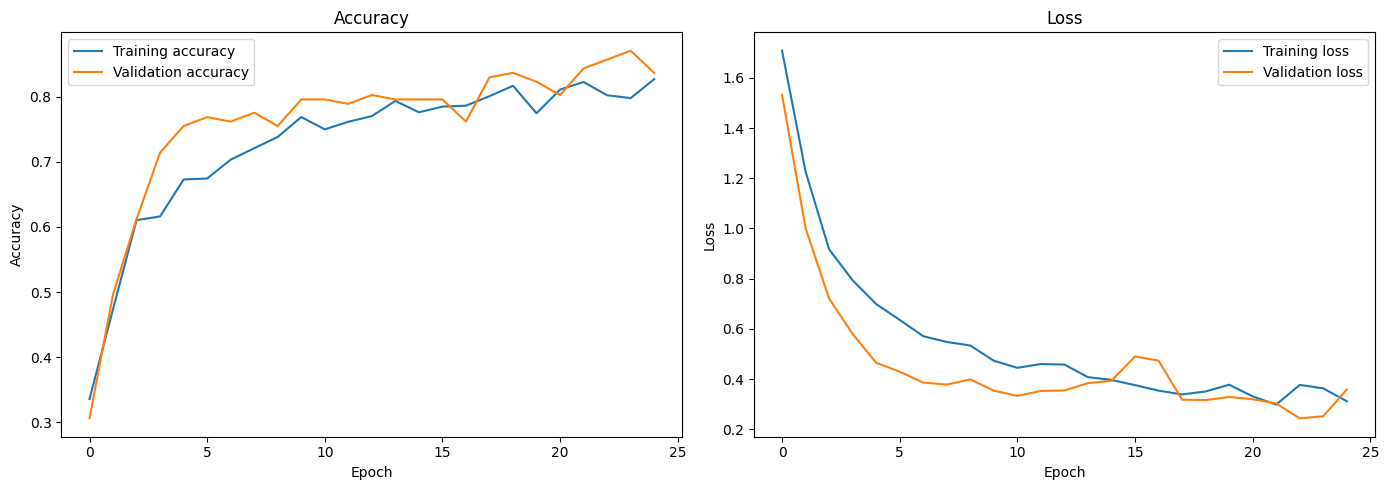

In [40]:
# 14. PLOT TRAINING CURVES
def combine_history(h1, h2, key):
    return h1.history.get(key, []) + h2.history.get(key, [])

train_acc = combine_history(history_head, history_fine, "accuracy")
val_acc = combine_history(history_head, history_fine, "val_accuracy")
train_loss = combine_history(history_head, history_fine, "loss")
val_loss = combine_history(history_head, history_fine, "val_loss")

history_df = pd.DataFrame({
    "train_accuracy": pd.Series(train_acc),
    "val_accuracy": pd.Series(val_acc),
    "train_loss": pd.Series(train_loss),
    "val_loss": pd.Series(val_loss)
})
history_df.to_csv(HISTORY_PATH, index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(train_acc, label="Training accuracy")
axes[0].plot(val_acc, label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(train_loss, label="Training loss")
axes[1].plot(val_loss, label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout()
plt.show()

## Cell 15: LOAD BEST SAVED MODEL

In [41]:
# 15. LOAD BEST SAVED MODEL
if MODEL_PATH.exists():
    model = tf.keras.models.load_model(
        MODEL_PATH,
        custom_objects={
            "loss_fn": categorical_focal_loss(gamma=1.5)
        }
    )
    print("Loaded best model:", MODEL_PATH)

Loaded best model: /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras


## Cell 16: FINAL TEST EVALUATION

In [42]:
# 16. FINAL TEST EVALUATION
# Run this only after training/model selection is complete.
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"\nTest accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

test_macro_recall = recall_score(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    average="macro",
    zero_division=0
)
print(f"Test macro recall: {test_macro_recall * 100:.2f}%")

report_dict = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(report_dict).transpose()
display(report_df)
report_df.to_csv(REPORT_PATH)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0,
    digits=4
))

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8378 - loss: 0.2161

Test accuracy: 83.78%
Test loss: 0.2161
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 194ms/step
Test macro recall: 78.30%


,precision,recall,f1-score,support
anger,0.842105,0.761905,0.800000,21.000000
contempt,1.000000,0.375000,0.545455,8.000000
disgust,0.916667,0.814815,0.862745,27.000000
fear,0.423077,1.000000,0.594595,11.000000
happy,0.882353,0.967742,0.923077,31.000000
sadness,1.000000,0.666667,0.800000,12.000000
surprise,1.000000,0.894737,0.944444,38.000000
accuracy,0.837838,0.837838,0.837838,0.837838
macro avg,0.866315,0.782981,0.781474,148.000000
weighted avg,0.894872,0.837838,0.845288,148.000000



Classification report:
              precision    recall  f1-score   support

       anger     0.8421    0.7619    0.8000        21
    contempt     1.0000    0.3750    0.5455         8
     disgust     0.9167    0.8148    0.8627        27
        fear     0.4231    1.0000    0.5946        11
       happy     0.8824    0.9677    0.9231        31
     sadness     1.0000    0.6667    0.8000        12
    surprise     1.0000    0.8947    0.9444        38

    accuracy                         0.8378       148
   macro avg     0.8663    0.7830    0.7815       148
weighted avg     0.8949    0.8378    0.8453       148



## Cell 17: CONFUSION MATRIX

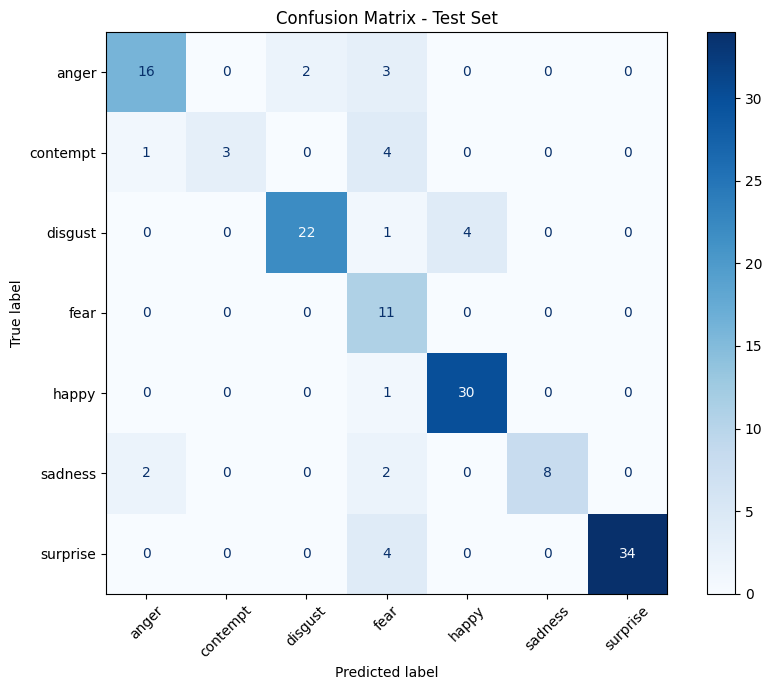

In [43]:
# 17. CONFUSION MATRIX
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(9, 7))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.show()

## Cell 18: CLASS-WISE RECALL CHART

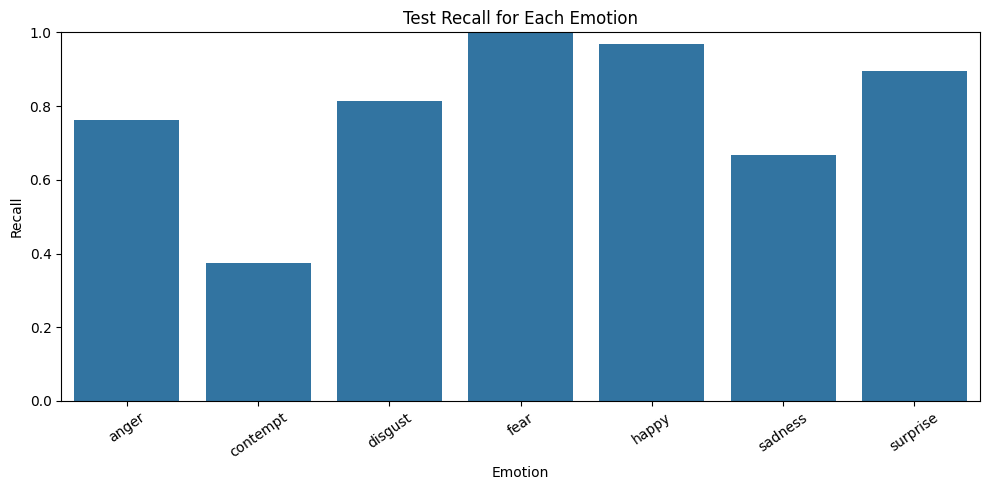

In [44]:
# 18. CLASS-WISE RECALL CHART
per_class_recall = recall_score(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    average=None,
    zero_division=0
)

recall_df = pd.DataFrame({
    "Emotion": class_names,
    "Recall": per_class_recall
})

plt.figure(figsize=(10, 5))
sns.barplot(data=recall_df, x="Emotion", y="Recall")
plt.ylim(0, 1)
plt.title("Test Recall for Each Emotion")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## Cell 19: SAVE MODEL AND LABELS

In [45]:
# 19. SAVE MODEL AND LABELS
model.save(MODEL_PATH)

with open(LABELS_PATH, "w") as f:
    json.dump(class_names, f, indent=4)

print("\nModel saved to:", MODEL_PATH)
print("Emotion labels saved to:", LABELS_PATH)
print("Classification report saved to:", REPORT_PATH)
print("Training history saved to:", HISTORY_PATH)


Model saved to: /content/drive/MyDrive/FER2013_Model/face_emotion_mobilenetv2.keras
Emotion labels saved to: /content/drive/MyDrive/FER2013_Model/emotion_labels.json
Classification report saved to: /content/drive/MyDrive/FER2013_Model/classification_report.csv
Training history saved to: /content/drive/MyDrive/FER2013_Model/training_history.csv


## Cell 20: SINGLE IMAGE PREDICTION

In [46]:
# 20. SINGLE IMAGE PREDICTION
from tensorflow.keras.utils import load_img, img_to_array

def predict_emotion_image(image_path, show_probabilities=True):
    image_path = Path(image_path)

    if not image_path.exists():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = load_img(
        image_path,
        target_size=(IMG_SIZE, IMG_SIZE),
        color_mode="rgb"
    )
    image_array = img_to_array(image).astype("float32")
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_emotion = class_names[predicted_index]
    confidence = float(probabilities[predicted_index])

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"{predicted_emotion} ({confidence * 100:.2f}%)")
    plt.axis("off")
    plt.show()

    print("Predicted emotion:", predicted_emotion)
    print(f"Model score: {confidence * 100:.2f}%")

    if show_probabilities:
        print("\nClass probabilities:")
        for name, probability in zip(class_names, probabilities):
            print(f"{name:15s}: {probability * 100:.2f}%")

    return predicted_emotion, confidence, probabilities

# Example:
# predict_emotion_image(
#     "/content/drive/MyDrive/FER2013/sadness/S066_004_00000009.png"
# )

## Final cell: Test an individual image

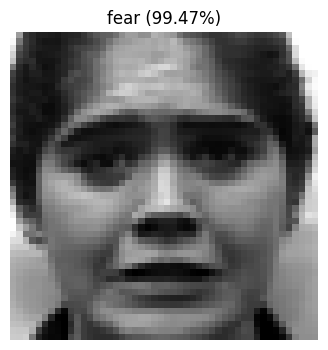

Predicted emotion: fear
Model score: 99.47%

Class probabilities:
anger          : 0.00%
contempt       : 0.00%
disgust        : 0.00%
fear           : 99.47%
happy          : 0.53%
sadness        : 0.00%
surprise       : 0.00%


('fear',
 0.994698166847229,
 array([5.3104515e-07, 2.6495206e-07, 1.0655581e-05, 9.9469817e-01,
        5.2838041e-03, 3.9878369e-06, 2.4779185e-06], dtype=float32))

In [47]:
predict_emotion_image(
    "/content/drive/MyDrive/FER2013/fear/S011_003_00000012.png"
)